In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from scipy import stats
df = pd.read_excel("zillow_SOLD_dataset.xlsx")
df.head(3)

,ZPID,Address,Zipcode,Price,Beds,Baths,Sqft,LotSize,HomeType,TaxValue,Zestimate,RentZestimate,Latitude,Longitude,Status,DetailLink
0,1156043,"8413 La Habra Ln, Indianapolis, IN 46236",46236,419000.0,5.0,4.0,2823.0,0.30,SINGLE_FAMILY,392200.0,410800.0,2480.0,39.909325,-85.96224,Sold,https://www.zillow.comhttps://www.zillow.com/h...
1,1232462,"9248 E 25th St, Indianapolis, IN 46229",46229,194900.0,3.0,2.0,2268.0,8712.00,SINGLE_FAMILY,149600.0,187800.0,1762.0,39.804340,-86.00374,Sold,https://www.zillow.comhttps://www.zillow.com/h...
2,1308773,"138 Demarest Dr, Indianapolis, IN 46214",46214,160000.0,3.0,2.0,1839.0,0.27,SINGLE_FAMILY,234300.0,234500.0,1844.0,39.767708,-86.29016,Sold,https://www.zillow.comhttps://www.zillow.com/h...


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 976 entries, 0 to 975
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   ZPID           976 non-null    int64  
 1   Address        976 non-null    object 
 2   Zipcode        976 non-null    object 
 3   Price          847 non-null    float64
 4   Beds           906 non-null    float64
 5   Baths          921 non-null    float64
 6   Sqft           891 non-null    float64
 7   LotSize        891 non-null    float64
 8   HomeType       976 non-null    object 
 9   TaxValue       809 non-null    float64
 10  Zestimate      736 non-null    float64
 11  RentZestimate  924 non-null    float64
 12  Latitude       954 non-null    float64
 13  Longitude      954 non-null    float64
 14  Status         976 non-null    object 
 15  DetailLink     976 non-null    object 
dtypes: float64(10), int64(1), object(5)
memory usage: 122.1+ KB


In [3]:
df.describe()

,ZPID,Price,Beds,Baths,Sqft,LotSize,TaxValue,Zestimate,RentZestimate,Latitude,Longitude
count,9.760000e+02,8.470000e+02,906.000000,921.000000,891.000000,891.000000,8.090000e+02,7.360000e+02,924.000000,954.000000,954.000000
mean,2.078859e+08,4.304712e+05,3.183223,2.359392,1971.258137,3126.694398,3.272879e+05,4.784136e+05,2553.531385,36.933360,-86.448209
std,4.057486e+08,3.698532e+05,1.109270,1.048830,980.885030,3753.153395,3.174063e+05,5.033003e+05,1359.177201,5.525867,9.513636
min,6.773400e+04,0.000000e+00,0.000000,0.000000,0.000000,0.000000,4.610000e+02,8.130000e+04,761.000000,24.596937,-117.683105
25%,3.555712e+07,2.250000e+05,3.000000,2.000000,1337.000000,0.532736,1.450000e+05,2.580000e+05,1731.500000,32.975038,-92.234140
50%,7.340816e+07,3.460000e+05,3.000000,2.000000,1815.000000,24.700000,2.524000e+05,3.666500e+05,2235.000000,38.216959,-84.500980
75%,2.353920e+08,5.200000e+05,4.000000,3.000000,2358.000000,6534.000000,4.029000e+05,5.430750e+05,2984.750000,41.046289,-80.604749
max,2.119314e+09,3.500000e+06,13.000000,7.000000,8344.000000,10848.000000,3.531483e+06,9.740600e+06,20016.000000,48.234196,-71.150360


In [4]:
df.isnull().sum()

ZPID               0
Address            0
Zipcode            0
Price            129
Beds              70
Baths             55
Sqft              85
LotSize           85
HomeType           0
TaxValue         167
Zestimate        240
RentZestimate     52
Latitude          22
Longitude         22
Status             0
DetailLink         0
dtype: int64

kiểm tra riêng số dòng bất thường:

In [5]:
print("Số dòng Price = 0:", (df['Price'] == 0).sum())
print("Số dòng Sqft = 0:", (df['Sqft'] == 0).sum())
print("Số dòng LotSize = 0:", (df['LotSize'] == 0).sum())
print("Số dòng Baths = 0:", (df['Baths'] == 0).sum())

Số dòng Price = 0: 2
Số dòng Sqft = 0: 11
Số dòng LotSize = 0: 8
Số dòng Baths = 0: 25


In [6]:
cols = [
    'Price',
    'Beds',
    'Baths',
    'Sqft',
    'LotSize',
    'HomeType',
    'TaxValue',
    'Latitude',
    'Longitude',
    'Zipcode'
]

df_model = df[cols].copy()

# Xóa dòng thiếu trong các biến cần dùng
df_clean = df_model.dropna().copy()

# Quy đổi LotSize
df_clean['LotSize'] = df_clean['LotSize'].apply(lambda x: x * 43560 if x < 50 else x)

# Loại bỏ giá trị không hợp lệ
df_clean = df_clean[
    (df_clean['Price'] > 0) &
    (df_clean['Sqft'] > 0) &
    (df_clean['LotSize'] > 0) &
    (df_clean['Beds'] > 0) &
    (df_clean['Baths'] > 0) &
    (df_clean['TaxValue'] > 0)
].copy()

# Tạo biến mới
df_clean['TaxPerSqft'] = df_clean['TaxValue'] / df_clean['Sqft']

# Kiểm tra lại thống kê mô tả
df_clean.describe()

,Price,Beds,Baths,Sqft,LotSize,TaxValue,Latitude,Longitude,TaxPerSqft
count,6.000000e+02,600.00000,600.000000,600.000000,6.000000e+02,6.000000e+02,600.000000,600.000000,600.000000
mean,4.529313e+05,3.27500,2.403333,2049.063333,3.424702e+04,3.348005e+05,37.304151,-85.515178,161.653438
std,3.668448e+05,0.94031,0.930286,933.103043,9.533804e+04,2.899995e+05,5.622265,8.874326,103.892230
min,1.000000e+04,1.00000,1.000000,212.000000,8.000000e+01,4.610000e+02,25.699663,-117.683105,0.384167
25%,2.500000e+05,3.00000,2.000000,1418.750000,6.534000e+03,1.599912e+05,33.442499,-89.737103,98.558887
50%,3.589500e+05,3.00000,2.000000,1852.000000,1.064824e+04,2.627805e+05,38.964008,-83.456732,144.995897
75%,5.350000e+05,4.00000,3.000000,2474.000000,2.337510e+04,4.090625e+05,41.500171,-80.567813,196.771191
max,3.500000e+06,8.00000,7.000000,7623.000000,1.075932e+06,2.751505e+06,47.314550,-71.150360,758.173077


In [7]:
from sklearn.preprocessing import LabelEncoder

le = LabelEncoder()
df_clean['HomeType_Code'] = le.fit_transform(df_clean['HomeType'])

# Để xem con số nào tương ứng với loại nhà nào:
mapping = dict(zip(le.classes_, le.transform(le.classes_)))
print(mapping)

{'CONDO': 0, 'MANUFACTURED': 1, 'MULTI_FAMILY': 2, 'SINGLE_FAMILY': 3, 'TOWNHOUSE': 4}


Kiểm tra xem đã xóa bao nhiêu dòng

In [8]:
print("Số dòng ban đầu:", df.shape[0])
print("Số dòng sau khi làm sạch:", df_clean.shape[0])
print("Số dòng bị loại:", df.shape[0] - df_clean.shape[0])

Số dòng ban đầu: 976
Số dòng sau khi làm sạch: 600
Số dòng bị loại: 376


Trong quá trình làm sạch dữ liệu, các quan sát có Price = 0 được loại bỏ vì giá bán bằng 0 không phản ánh giá trị giao dịch thực tế của bất động sản, mà nhiều khả năng là dữ liệu thiếu hoặc lỗi nhập liệu. Ngoài ra, các quan sát có Sqft = 0, LotSize = 0, Beds = 0, Baths = 0 hoặc TaxValue <= 0 cũng được loại bỏ nhằm đảm bảo các biến giải thích có ý nghĩa thực tế. Sau khi làm sạch, biến TaxPerSqft được tính lại bằng cách lấy TaxValue chia cho Sqft.

Thống kê mô tả

In [9]:
numeric_cols = [
    'Price',
    'Beds',
    'Baths',
    'Sqft',
    'LotSize',
    'TaxValue',
    'TaxPerSqft',
    'Latitude',
    'Longitude',
    'HomeType_Code'
]
desc_stats = df_clean[numeric_cols].describe()
desc_stats

,Price,Beds,Baths,Sqft,LotSize,TaxValue,TaxPerSqft,Latitude,Longitude,HomeType_Code
count,6.000000e+02,600.00000,600.000000,600.000000,6.000000e+02,6.000000e+02,600.000000,600.000000,600.000000,600.000000
mean,4.529313e+05,3.27500,2.403333,2049.063333,3.424702e+04,3.348005e+05,161.653438,37.304151,-85.515178,2.923333
std,3.668448e+05,0.94031,0.930286,933.103043,9.533804e+04,2.899995e+05,103.892230,5.622265,8.874326,0.628315
min,1.000000e+04,1.00000,1.000000,212.000000,8.000000e+01,4.610000e+02,0.384167,25.699663,-117.683105,0.000000
25%,2.500000e+05,3.00000,2.000000,1418.750000,6.534000e+03,1.599912e+05,98.558887,33.442499,-89.737103,3.000000
50%,3.589500e+05,3.00000,2.000000,1852.000000,1.064824e+04,2.627805e+05,144.995897,38.964008,-83.456732,3.000000
75%,5.350000e+05,4.00000,3.000000,2474.000000,2.337510e+04,4.090625e+05,196.771191,41.500171,-80.567813,3.000000
max,3.500000e+06,8.00000,7.000000,7623.000000,1.075932e+06,2.751505e+06,758.173077,47.314550,-71.150360,4.000000


Phân tích khám phá (EDA)

Biểu đồ phân phối giá bán nhà

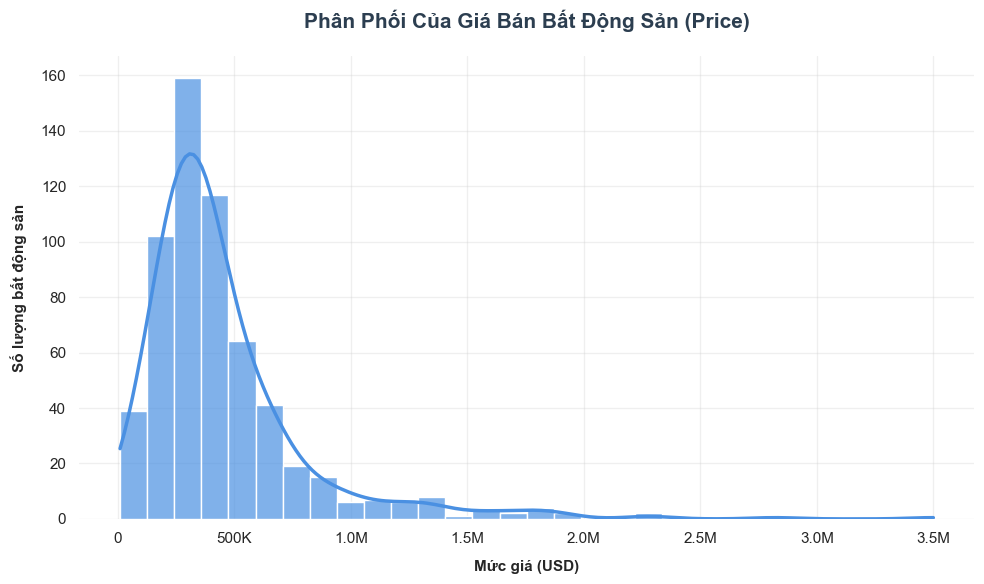

In [10]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# 1. Thiết lập style nền trắng có lưới mờ hiện đại
sns.set_theme(style="whitegrid", rc={"grid.alpha": 0.3})
plt.figure(figsize=(10, 6), dpi=100) # Tăng độ nét dpi

# 2. Vẽ biểu đồ phân phối (Histogram + KDE)
sns.histplot(
    data=df_clean, 
    x="Price", 
    kde=True, 
    bins=30, 
    color="#4a90e2",       # Màu xanh hiện đại, nhã nhặn hơn hoàng gia (royalblue)
    alpha=0.7,             # Làm mờ nhẹ các thanh cột
    edgecolor="white",     # Tạo đường viền trắng mảnh giữa các cột cho sắc nét
    line_kws={"linewidth": 2.5, "color": "#ff7675"} # Đường KDE màu hồng cam nổi bật
)

# 3. ĐỊNH DẠNG TRỤC X: Rút gọn số tiền lớn thành dạng K hoặc M (Ví dụ: 1,000,000 -> 1.0M)
def price_formatter(x, pos):
    if x >= 1e6:
        return f'{x*1e-6:.1f}M'
    elif x >= 1e3:
        return f'{x*1e-3:.0f}K'
    return f'{x:.0f}'

plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(price_formatter))

# 4. Tinh chỉnh tiêu đề và nhãn trục (Font chữ phân cấp rõ ràng)
plt.title("Phân Phối Của Giá Bán Bất Động Sản (Price)", fontsize=15, fontweight="bold", pad=20, color='#2c3e50')
plt.xlabel("Mức giá (USD)", fontsize=11, labelpad=10, fontweight='semibold')
plt.ylabel("Số lượng bất động sản", fontsize=11, labelpad=10, fontweight='semibold')

# 5. Loại bỏ viền trên và viền phải cho thanh thoát
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

Diện tích nhà và giá bán

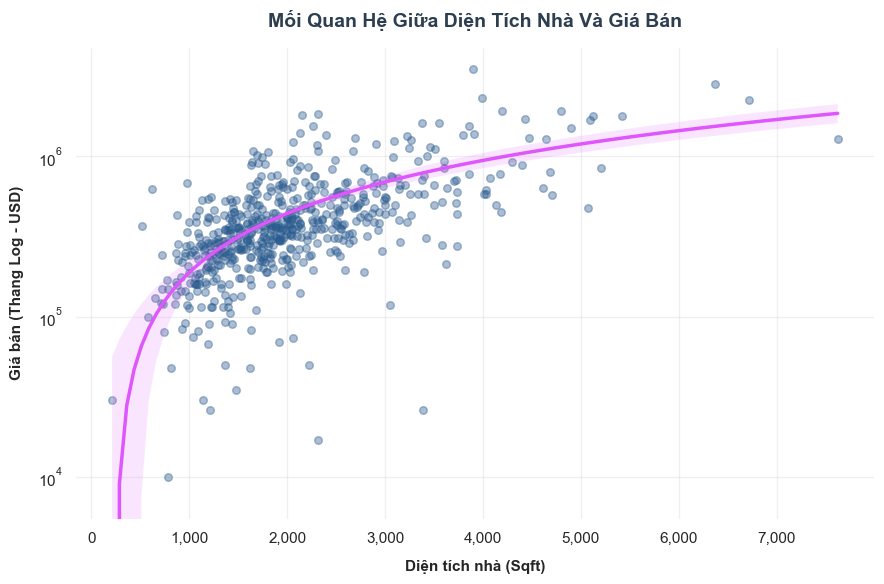

In [11]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# 1. Khởi tạo style nền trắng có lưới mờ thanh lịch
sns.set_theme(style="whitegrid", rc={"grid.alpha": 0.3})
plt.figure(figsize=(9, 6), dpi=100)

# 2. Vẽ đồ thị hồi quy tuyến tính
sns.regplot(
    data=df_clean,
    x='Sqft',
    y='Price',
    scatter_kws={
        'alpha': 0.4,          # Làm mờ vừa phải để thấy rõ mật độ tập trung dữ liệu
        's': 30,               # Kích thước chấm vừa vặn, tinh tế
        'color': '#2b5c8f'     # Màu xanh Prussian cổ điển
    },
    line_kws={
        'color': '#e056fd',    # Đường hồi quy màu tím hồng neon/magenta để cực kỳ nổi bật
        'linewidth': 2.5
    }
)

# 3. ĐỊNH DẠNG TRỤC X (Diện tích: Ví dụ 2,500 Sqft)
# Thêm dấu phẩy phân cách hàng nghìn cho diện tích dễ đọc
plt.gca().xaxis.set_major_formatter(ticker.FuncFormatter(lambda x, pos: f'{x:,.0f}'))

# 4. ĐỊNH DẠNG TRỤC Y (Giá bán: Ví dụ 500K, 1.2M)
# Hàm thông minh tự động rút gọn số tiền lớn thành K (Nghìn) hoặc M (Triệu)
def price_formatter(x, pos):
    if x >= 1e6:
        return f'{x*1e-6:.1f}M'
    elif x >= 1e3:
        return f'{x*1e-3:.0f}K'
    return f'{x:.0f}'

plt.gca().yaxis.set_major_formatter(ticker.FuncFormatter(price_formatter))

# 5. BẬT LOG SCALE CHO TRỤC Y (Nếu bạn muốn khớp với nhãn Log(Price) ban đầu)
# Lệnh này giúp nén các khoảng giá quá cao lại, làm đường regplot chuẩn xác hơn
plt.yscale('log')

# 6. Thiết lập tiêu đề và nhãn trục chỉn chu
plt.title('Mối Quan Hệ Giữa Diện Tích Nhà Và Giá Bán', fontsize=14, fontweight='bold', pad=15, color='#2c3e50')
plt.xlabel('Diện tích nhà (Sqft)', fontsize=11, labelpad=10, fontweight='semibold')
plt.ylabel('Giá bán (Thang Log - USD)', fontsize=11, labelpad=10, fontweight='semibold')

# 7. Tối giản khung viền (Xóa đường biên trên và phải)
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

TaxValue và giá bán

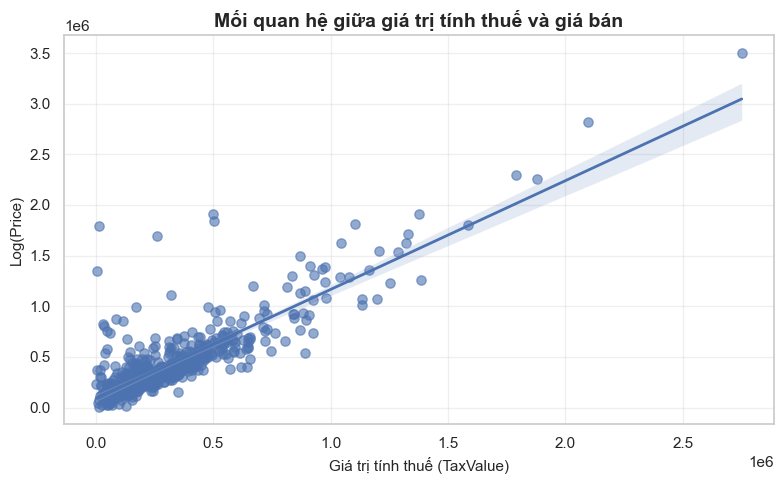

In [12]:
plt.figure(figsize=(8, 5))

sns.regplot(
    data=df_clean,
    x='TaxValue',
    y='Price',
    scatter_kws={'alpha': 0.6, 's': 45},
    line_kws={'linewidth': 2}
)

plt.title('Mối quan hệ giữa giá trị tính thuế và giá bán', fontsize=14, fontweight='bold')
plt.xlabel('Giá trị tính thuế (TaxValue)', fontsize=11)
plt.ylabel('Log(Price)', fontsize=11)
plt.tight_layout()
plt.show()

Số phòng tắm và giá bán

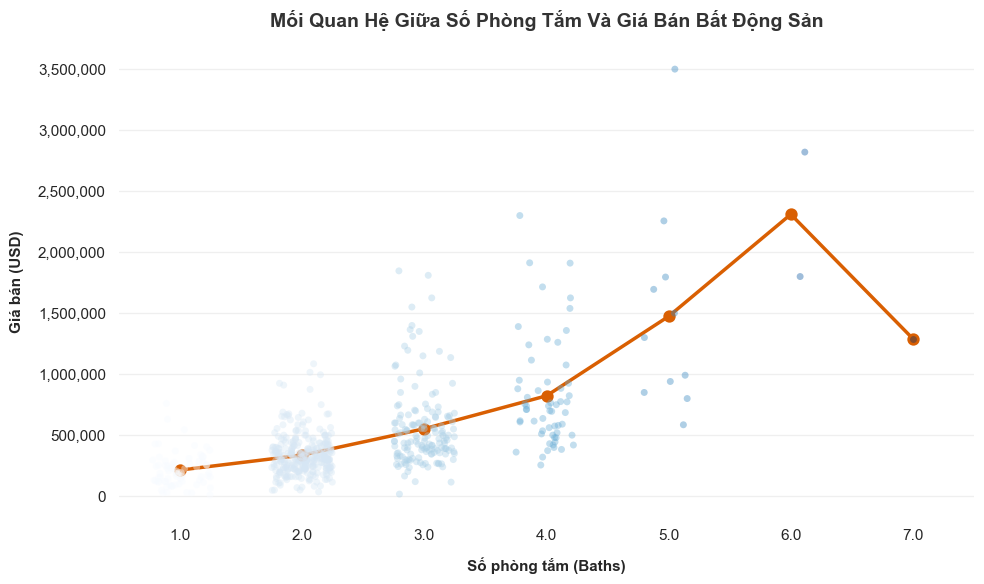

In [13]:
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

# 1. Thiết lập style hiện đại và tinh tế
sns.set_theme(style="whitegrid", rc={"grid.alpha": 0.3})
plt.figure(figsize=(10, 6), dpi=100)  # Tăng nhẹ kích thước và độ nét (dpi)

# 2. Vẽ stripplot với palette màu nhã nhặn (độ trong suốt alpha hợp lý)
sns.stripplot(
    data=df_clean,
    x='Baths',
    y='Price',
    palette="Blues",       # Tạo dải màu xanh từ nhạt đến đậm theo số phòng tắm
    alpha=0.4,             # Làm mờ bớt các điểm dữ liệu để không bị rối
    jitter=0.25,           # Độ phân tán vừa phải
    size=5,                # Kích thước chấm vừa vặn
    hue='Baths',           # Tránh cảnh báo ẩn của Seaborn mới
    legend=False
)

# 3. Vẽ pointplot làm nổi bật đường xu hướng trung bình
sns.pointplot(
    data=df_clean,
    x='Baths',
    y='Price',
    estimator='mean',
    errorbar=None,
    color='#d95f02',       # Màu cam đậm tương phản cao, rất chuyên nghiệp
    linewidth=2.5,         # Đường nối dày hơn một chút
    markers='o',           # Điểm nút hình tròn rõ ràng
    markersize=7
)

# 4. Định dạng trục Y hiển thị số tiền có dấu phẩy (Ví dụ: 1,250,000)
# Cách này giúp "hiển thị đúng giá" mà trực quan, gọn gàng hơn style 'plain'
formatter = ticker.FuncFormatter(lambda x, pos: f'{x:,.0f}')
plt.gca().yaxis.set_major_formatter(formatter)

# 5. Tinh chỉnh Tiêu đề và Nhãn trục (Sử dụng font chữ phân cấp rõ ràng)
plt.title('Mối Quan Hệ Giữa Số Phòng Tắm Và Giá Bán Bất Động Sản', 
          fontsize=14, fontweight='bold', pad=15, color='#333333')

plt.xlabel('Số phòng tắm (Baths)', fontsize=11, labelpad=10, fontweight='semibold')
plt.ylabel('Giá bán (USD)', fontsize=11, labelpad=10, fontweight='semibold')

# 6. Loại bỏ đường viền hộp (spines) ở phía trên và bên phải để biểu đồ thanh thoát
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

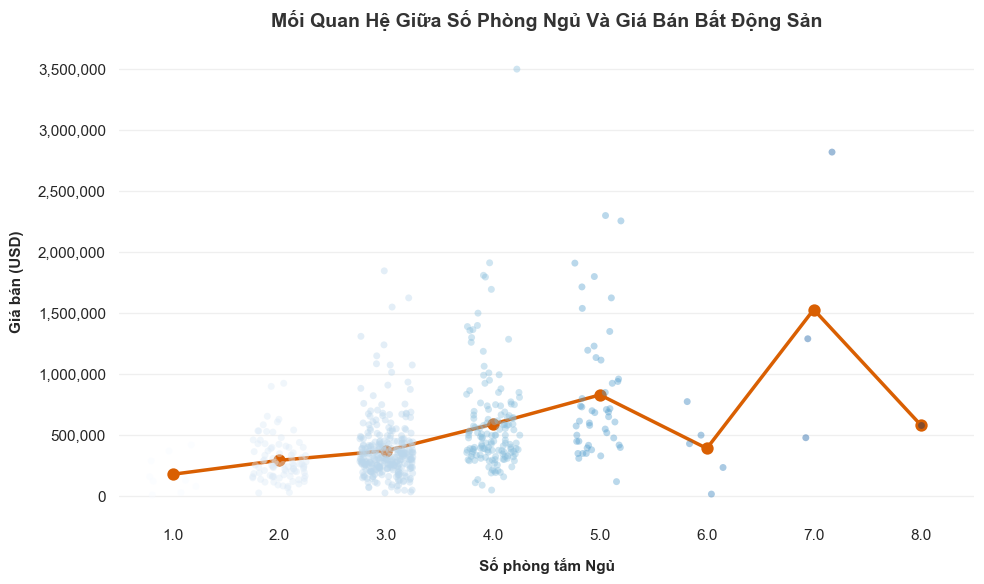

In [14]:
# 1. Thiết lập style hiện đại và tinh tế
sns.set_theme(style="whitegrid", rc={"grid.alpha": 0.3})
plt.figure(figsize=(10, 6), dpi=100)  # Tăng nhẹ kích thước và độ nét (dpi)

# 2. Vẽ stripplot với palette màu nhã nhặn (độ trong suốt alpha hợp lý)
sns.stripplot(
    data=df_clean,
    x='Beds',
    y='Price',
    palette="Blues",       # Tạo dải màu xanh từ nhạt đến đậm theo số phòng tắm
    alpha=0.4,             # Làm mờ bớt các điểm dữ liệu để không bị rối
    jitter=0.25,           # Độ phân tán vừa phải
    size=5,                # Kích thước chấm vừa vặn
    hue='Beds',           # Tránh cảnh báo ẩn của Seaborn mới
    legend=False
)

# 3. Vẽ pointplot làm nổi bật đường xu hướng trung bình
sns.pointplot(
    data=df_clean,
    x='Beds',
    y='Price',
    estimator='mean',
    errorbar=None,
    color='#d95f02',       # Màu cam đậm tương phản cao, rất chuyên nghiệp
    linewidth=2.5,         # Đường nối dày hơn một chút
    markers='o',           # Điểm nút hình tròn rõ ràng
    markersize=7
)

# 4. Định dạng trục Y hiển thị số tiền có dấu phẩy (Ví dụ: 1,250,000)
# Cách này giúp "hiển thị đúng giá" mà trực quan, gọn gàng hơn style 'plain'
formatter = ticker.FuncFormatter(lambda x, pos: f'{x:,.0f}')
plt.gca().yaxis.set_major_formatter(formatter)

# 5. Tinh chỉnh Tiêu đề và Nhãn trục (Sử dụng font chữ phân cấp rõ ràng)
plt.title('Mối Quan Hệ Giữa Số Phòng Ngủ Và Giá Bán Bất Động Sản', 
          fontsize=14, fontweight='bold', pad=15, color='#333333')

plt.xlabel('Số phòng tắm Ngủ', fontsize=11, labelpad=10, fontweight='semibold')
plt.ylabel('Giá bán (USD)', fontsize=11, labelpad=10, fontweight='semibold')

# 6. Loại bỏ đường viền hộp (spines) ở phía trên và bên phải để biểu đồ thanh thoát
sns.despine(left=True, bottom=True)

plt.tight_layout()
plt.show()

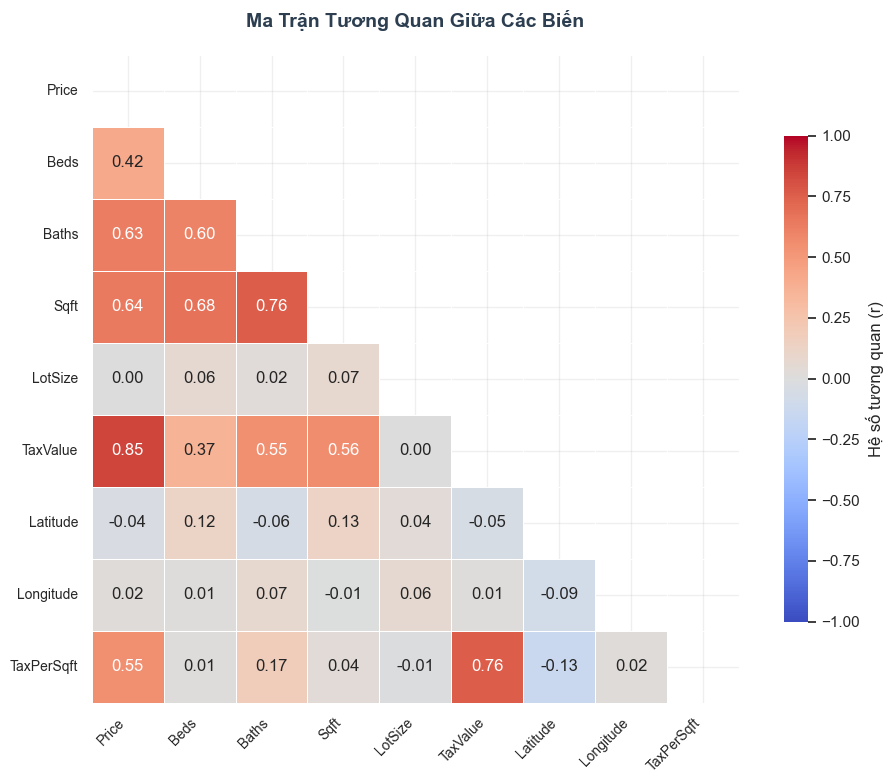

In [15]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Tính toán ma trận tương quan
corr = df_clean[['Price', 'Beds', 'Baths', 'Sqft', 'LotSize', 'TaxValue', 'Latitude', 'Longitude', 'TaxPerSqft']].corr()

# 2. Tạo một lớp mặt nạ (mask) để che đi một nửa tam giác phía trên
# Điều này giúp biểu đồ thoáng hơn, không bị lặp thông tin đối xứng
mask = np.triu(np.ones_like(corr, dtype=bool))

# 3. Khởi tạo không gian vẽ
plt.figure(figsize=(10, 8), dpi=100)

# 4. Vẽ Heatmap với cấu hình cao cấp
sns.heatmap(
    corr,
    mask=mask,                # Áp dụng mặt nạ che nửa trên
    annot=True,               # Hiển thị số
    fmt='.2f',                # Làm tròn đúng 2 chữ số thập phân
    cmap='coolwarm',          # Bảng màu chuẩn cho tương quan (Lạnh -> Nóng)
    vmax=1, vmin=-1,          # Cố định giới hạn thang đo từ -1 đến 1
    center=0,                 # Điểm trung tâm là 0 (màu trung tính)
    square=True,              # Buộc các ô phải là hình vuông hoàn hảo
    linewidths=0.5,           # Tạo đường ranh giới mảnh giữa các ô
    cbar_kws={"shrink": 0.75, "label": "Hệ số tương quan (r)"} # Thu nhỏ thanh màu cho cân đối
)

# 5. Tinh chỉnh tiêu đề và các nhãn trục
plt.title("Ma Trận Tương Quan Giữa Các Biến", fontsize=14, fontweight="bold", pad=20, color='#2c3e50')

# Xoay nhãn trục X để không bị chữ đè lên nhau
plt.xticks(rotation=45, ha='right', fontsize=10)
plt.yticks(rotation=0, fontsize=10)

plt.tight_layout()
plt.show()

# Xây dựng mô hình

## 1. Chuẩn bị biến cho mô hình

Mô hình đề xuất:

$$\ln(Price_i)=\beta_0+\beta_1\ln(Sqft_i)+\beta_2\ln(LotSize_i)+\beta_3Beds_i+\beta_4Baths_i+\beta_5\ln(TaxValue_i)+\beta_6Latitude_i+\beta_7Longitude_i+\sum\gamma_kHomeType_{ki}+u_i$$

Trong đó `Price` là giá bán nhà; `Sqft` là diện tích sử dụng; `LotSize` là diện tích lô đất đã quy đổi về sqft; `Beds`, `Baths` là số phòng ngủ và phòng tắm; `TaxValue` là giá trị tính thuế; `Latitude`, `Longitude` thể hiện vị trí địa lý; `HomeType_*` là nhóm biến giả cho loại nhà.

In [16]:
import statsmodels.api as sm
from statsmodels.stats.outliers_influence import OLSInfluence, variance_inflation_factor
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.stattools import jarque_bera
from scipy import stats
from IPython.display import display

# Tạo bản sao dữ liệu để xây dựng mô hình
model_df = df_clean.copy().reset_index(drop=True)

# Biến đổi logarit cho các biến có giá trị lớn và lệch phải
# Mục đích: thu hẹp thang đo, giảm ảnh hưởng của giá trị ngoại lai
# và giúp mô hình hồi quy ổn định hơn
model_df['LogPrice'] = np.log(model_df['Price'])
model_df['LogSqft'] = np.log(model_df['Sqft'])
model_df['LogLotSize'] = np.log(model_df['LotSize'])
model_df['LogTaxValue'] = np.log(model_df['TaxValue'])

# Tạo biến giả cho biến định tính HomeType
# drop_first=True giúp tránh hiện tượng đa cộng tuyến giả
home_dummies = pd.get_dummies(
    model_df['HomeType'],
    prefix='HomeType',
    drop_first=True,
    dtype=int
)

# Ghép các biến giả vào bộ dữ liệu
model_df = pd.concat([model_df, home_dummies], axis=1)

# Danh sách biến độc lập sử dụng trong mô hình
feature_cols = [
    'LogSqft', 'LogLotSize', 'Beds', 'Baths', 'LogTaxValue',
    'Latitude', 'Longitude'
] + list(home_dummies.columns)

# Khai báo biến độc lập X và biến phụ thuộc y
X = sm.add_constant(model_df[feature_cols])
y = model_df['LogPrice']

print('Số quan sát được sử dụng trong mô hình:', len(model_df))

print('Các biến độc lập được sử dụng trong mô hình:')
display(feature_cols)

print()
print('Các loại hình nhà có trong dữ liệu:')
print(sorted(model_df['HomeType'].unique()))

Số quan sát được sử dụng trong mô hình: 600
Các biến độc lập được sử dụng trong mô hình:


['LogSqft',
 'LogLotSize',
 'Beds',
 'Baths',
 'LogTaxValue',
 'Latitude',
 'Longitude',
 'HomeType_MANUFACTURED',
 'HomeType_MULTI_FAMILY',
 'HomeType_SINGLE_FAMILY',
 'HomeType_TOWNHOUSE']


Các loại hình nhà có trong dữ liệu:
['CONDO', 'MANUFACTURED', 'MULTI_FAMILY', 'SINGLE_FAMILY', 'TOWNHOUSE']


Do gia ban nha va cac bien quy mo nhu `Sqft`, `LotSize`, `TaxValue` co do chenh lech lon va thuong lech phai, mo hinh su dung logarit cho cac bien nay. Cach bien doi log giup thu hep thang do, giam anh huong cua cac gia tri rat lon va lam quan he giua gia nha voi cac bien giai thich gan tuyen tinh hon.

Bien `HomeType` la bien phan loai nen duoc dua vao mo hinh duoi dang bien gia. Mot nhom nha duoc dung lam nhom co so; cac he so `HomeType_*` the hien muc chenh lech cua tung loai nha so voi nhom co so khi cac yeu to khac khong doi.


## 2. Ước lượng mô hình hồi quy tuyến tính bội

Các hệ số được ước lượng bằng phương pháp bình phương tối thiểu OLS

In [17]:
model = sm.OLS(y, X).fit()

print(model.summary())


                            OLS Regression Results                            
Dep. Variable:               LogPrice   R-squared:                       0.605
Model:                            OLS   Adj. R-squared:                  0.598
Method:                 Least Squares   F-statistic:                     81.84
Date:                Sat, 16 May 2026   Prob (F-statistic):          7.28e-111
Time:                        09:03:04   Log-Likelihood:                -368.71
No. Observations:                 600   AIC:                             761.4
Df Residuals:                     588   BIC:                             814.2
Df Model:                          11                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const                      5

**Nhan xet ket qua uoc luong OLS**

Mo hinh duoc uoc luong tren 600 quan sat voi 11 bien doc lap. He so xac dinh `R^2 = 0.6049` va `R^2 hieu chinh = 0.5975`, cho thay mo hinh giai thich duoc khoang 60% bien dong cua `LogPrice`. Day la muc phu hop tuong doi tot doi voi du lieu gia bat dong san, vi gia nha con chiu tac dong boi nhieu yeu to kho quan sat nhu tinh trang nha, noi that, tien ich xung quanh, thoi diem giao dich va dac diem khu dan cu.

Cac bien co y nghia thong ke ro nhat la `LogSqft`, `Baths` va `LogTaxValue` voi p-value rat nho. Khi giu cac yeu to khac khong doi, dien tich su dung lon hon, so phong tam nhieu hon va gia tri tinh thue cao hon deu gan voi gia ban cao hon. Trong do, `LogTaxValue` co he so lon va muc y nghia manh nhat, cho thay bien nay phan anh kha tot gia tri thi truong cua bat dong san.

Cac bien `LogLotSize`, `Beds`, `Latitude`, `Longitude` va hau het bien gia `HomeType` chua co y nghia thong ke trong mo hinh nay. Dieu do khong co nghia la cac yeu to nay hoan toan khong anh huong den gia nha, ma la sau khi da kiem soat `Sqft`, `Baths`, `TaxValue` va cac bien con lai, du lieu hien tai chua cung cap du bang chung de ket luan tac dong rieng cua chung khac 0.

Phuong trinh hoi quy uoc luong la:

$$
\widehat{LogPrice}=5.8923+0.3166LogSqft-0.0029LogLotSize-0.0174Beds+0.2210Baths+0.3451LogTaxValue-0.0046Latitude+0.0027Longitude-0.0206HomeType\_MANUFACTURED-0.0340HomeType\_MULTI\_FAMILY+0.2098HomeType\_SINGLE\_FAMILY+0.1583HomeType\_TOWNHOUSE
$$


## 3. Ước lượng phương sai sai số ngẫu nhiên

Theo bài thực hành 1:

$$\hat{\sigma}^2=\frac{SSE}{n-k-1}=\frac{\sum e_i^2}{n-k-1}$$

Trong đó `n` là số quan sát, `k` là số biến độc lập không tính hằng số.

In [18]:
residual = model.resid
SSE = float(np.sum(residual ** 2))
n = int(model.nobs)
k = int(model.df_model)
df_resid = int(model.df_resid)
sigma2 = SSE / df_resid
sigma = np.sqrt(sigma2)

print('SSE =', SSE)
print('Residual degrees of freedom =', df_resid)
print('Error variance =', sigma2)
print('Error standard deviation =', sigma)


SSE = 120.07253741477727
Residual degrees of freedom = 588
Error variance = 0.20420499560336272
Error standard deviation = 0.4518904685909659


**Nhan xet phuong sai sai so**

Tong binh phuong phan du `SSE = 120.0725`. Voi 600 quan sat va 11 bien doc lap, bac tu do phan du la 588. Phuong sai sai so uoc luong bang `0.2042`, tuong ung do lech chuan sai so khoang `0.4519` tren thang log cua gia ban.

Vi bien phu thuoc la `LogPrice`, do lech chuan phan du nay cho thay sai so du bao cua mo hinh van con dang ke. Noi cach khac, mo hinh nam bat duoc xu huong chinh cua gia nha nhung chua the du bao chinh xac cho tung can nha rieng le, dac biet voi cac quan sat co dac diem bat thuong hoac thieu cac thong tin quan trong chua co trong du lieu.


# 4. Ước lượng khoảng cho các hệ số hồi quy của mô hình trên với độ tin cậy 95%.

In [19]:
summary_stats = pd.DataFrame({
    'Hệ số': model.params,
    'Sai số chuẩn': model.bse,
    'Giá trị t': model.tvalues,
    'P-value': model.pvalues,
    'Cận dưới (95%)': model.conf_int(0.05)[0],
    'Cận trên (95%)': model.conf_int(0.05)[1]
})
summary_stats.round(4)


,Hệ số,Sai số chuẩn,Giá trị t,P-value,Cận dưới (95%),Cận trên (95%)
const,5.8923,0.5351,11.0115,0.0000,4.8414,6.9433
LogSqft,0.3166,0.0772,4.1000,0.0000,0.1649,0.4682
LogLotSize,-0.0029,0.0171,-0.1712,0.8641,-0.0364,0.0306
Beds,-0.0174,0.0290,-0.5976,0.5503,-0.0744,0.0397
Baths,0.2210,0.0323,6.8411,0.0000,0.1576,0.2844
LogTaxValue,0.3451,0.0241,14.3476,0.0000,0.2979,0.3923
Latitude,-0.0046,0.0035,-1.3458,0.1789,-0.0114,0.0021
Longitude,0.0027,0.0021,1.2929,0.1965,-0.0014,0.0069
HomeType_MANUFACTURED,-0.0206,0.1784,-0.1156,0.9080,-0.3711,0.3299
HomeType_MULTI_FAMILY,-0.0340,0.1889,-0.1802,0.8570,-0.4050,0.3369


## 5. Kiểm định ý nghĩa từng hệ số

Với từng hệ số riêng:

$$H_0:\beta_j=0$$
$$H_1:\beta_j\ne0$$

Nếu `p-value < α` thì bác bỏ `H0`, nghĩa là biến đó có ảnh hưởng có ý nghĩa thống kê đến `LogPrice`.

In [20]:
print()
print('Gia thuyet kiem dinh:')
print('H0: beta_i = 0')
print('H1: beta_i != 0')

alpha = 0.05
result = pd.DataFrame({
    'Coefficient': model.params,
    'Std Error': model.bse,
    't_stat': model.tvalues,
    'p_value': model.pvalues
})
p_value = model.pvalues

print(result)



Gia thuyet kiem dinh:
H0: beta_i = 0
H1: beta_i != 0
                        Coefficient  Std Error     t_stat       p_value
const                      5.892336   0.535107  11.011508  9.087645e-26
LogSqft                    0.316553   0.077207   4.100025  4.712620e-05
LogLotSize                -0.002920   0.017056  -0.171211  8.641171e-01
Beds                      -0.017358   0.029046  -0.597617  5.503259e-01
Baths                      0.220996   0.032304   6.841128  1.976644e-11
LogTaxValue                0.345093   0.024052  14.347620  3.028536e-40
Latitude                  -0.004645   0.003451  -1.345780  1.788920e-01
Longitude                  0.002744   0.002122   1.292930  1.965431e-01
HomeType_MANUFACTURED     -0.020622   0.178449  -0.115564  9.080377e-01
HomeType_MULTI_FAMILY     -0.034041   0.188889  -0.180217  8.570442e-01
HomeType_SINGLE_FAMILY     0.209791   0.119515   1.755350  7.972018e-02
HomeType_TOWNHOUSE         0.158322   0.140636   1.125759  2.607267e-01


In [21]:
print("\nKết luận kiểm định")

for var in result.index:
    
    if p_value[var] < alpha:
        
        print(var,"→ Bác bỏ H0: hệ số có ý nghĩa")
        
    else:
        print(var,"→ Không bác bỏ H0")


Kết luận kiểm định
const → Bác bỏ H0: hệ số có ý nghĩa
LogSqft → Bác bỏ H0: hệ số có ý nghĩa
LogLotSize → Không bác bỏ H0
Beds → Không bác bỏ H0
Baths → Bác bỏ H0: hệ số có ý nghĩa
LogTaxValue → Bác bỏ H0: hệ số có ý nghĩa
Latitude → Không bác bỏ H0
Longitude → Không bác bỏ H0
HomeType_MANUFACTURED → Không bác bỏ H0
HomeType_MULTI_FAMILY → Không bác bỏ H0
HomeType_SINGLE_FAMILY → Không bác bỏ H0
HomeType_TOWNHOUSE → Không bác bỏ H0


**Nhan xet khoang tin cay va kiem dinh tung he so**

Khoang tin cay 95% cua `LogSqft`, `Baths` va `LogTaxValue` deu khong chua 0, phu hop voi ket qua kiem dinh t rang ba bien nay co y nghia thong ke o muc 5%. Cu the, he so cua `LogSqft` nam trong khoang `[0.1649; 0.4682]`, he so cua `Baths` nam trong khoang `[0.1576; 0.2844]`, va he so cua `LogTaxValue` nam trong khoang `[0.2979; 0.3923]`.

Cac bien con lai co khoang tin cay chua 0 nen chua du bang chung de ket luan tac dong rieng cua chung co y nghia thong ke. Dang chu y, `HomeType_SINGLE_FAMILY` co p-value khoang `0.0797`, gan muc 10% nhung van chua dat muc y nghia 5%, vi vay khong nen ket luan chac chan rang loai nha nay co tac dong khac biet so voi nhom co so trong mo hinh hien tai.


## 6. Do phu hop mo hinh va kiem dinh F tong the

He so xac dinh:

$$R^2=1-\frac{SSE}{SST}$$

Kiem dinh F tong the:

$$H_0:\beta_1=\beta_2=...=\beta_k=0$$
$$H_1:\text{Co it nhat mot he so khac 0}$$

Ket qua cho thay `R^2 = 0.6049`, `R^2 hieu chinh = 0.5975`, `F-statistic = 81.84` va p-value cua kiem dinh F xap xi `7.28e-111`. Vi p-value rat nho, bac bo `H0` o muc y nghia 5%. Nhu vay, xet tong the, cac bien doc lap trong mo hinh co kha nang giai thich bien dong cua gia ban nha.


In [22]:
fit_table = pd.DataFrame({
    'Chỉ tiêu': ['R^2', 'R^2 hiệu chỉnh', 'F-statistic', 'p-value của F', 'AIC', 'BIC'],
    'Giá trị': [model.rsquared, model.rsquared_adj, model.fvalue, model.f_pvalue, model.aic, model.bic]
})
display(fit_table)

if model.f_pvalue < 0.05:
    print('Bác bỏ H0 của kiểm định F: mô hình có ý nghĩa thống kê tổng thể ở mức 5%.')
else:
    print('Chưa bác bỏ H0 của kiểm định F: mô hình chưa có ý nghĩa thống kê tổng thể ở mức 5%.')

,Chỉ tiêu,Giá trị
0,R^2,6.048950e-01
1,R^2 hiệu chỉnh,5.975036e-01
2,F-statistic,8.183747e+01
3,p-value của F,7.282055e-111
4,AIC,7.614261e+02
5,BIC,8.141892e+02


Bác bỏ H0 của kiểm định F: mô hình có ý nghĩa thống kê tổng thể ở mức 5%.


## 7. He so hoi quy chuan hoa

De so sanh muc do anh huong tuong doi giua cac bien co don vi do khac nhau, chuan hoa `X` va `y` ve trung binh 0, do lech chuan 1 roi hoi quy lai.

**Nhan xet he so chuan hoa**

Ket qua he so chuan hoa cho thay `LogTaxValue` co anh huong tuong doi manh nhat den `LogPrice` voi he so chuan hoa khoang `0.4457`. Tiep theo la `Baths` voi he so khoang `0.2886`, roi den `LogSqft` voi he so khoang `0.1903`. Dieu nay cung co ket luan tu bang OLS: gia tri tinh thue, so phong tam va dien tich su dung la ba yeu to noi bat nhat trong mo hinh.

Cac bien con lai co he so chuan hoa nho hon dang ke, cho thay dong gop bien cua chung vao bien dong gia ban thap hon sau khi da kiem soat cac bien chinh.


In [23]:
X_std = model_df[feature_cols].copy()
y_std = model_df['LogPrice'].copy()

X_std = (X_std - X_std.mean()) / X_std.std(ddof=0)
y_std = (y_std - y_std.mean()) / y_std.std(ddof=0)

std_model = sm.OLS(y_std, sm.add_constant(X_std)).fit()
std_coef = pd.DataFrame({
    'Variable': feature_cols,
    'Standardized coefficient': std_model.params[feature_cols].values
}).sort_values('Standardized coefficient', key=lambda s: s.abs(), ascending=False)

display(std_coef.round(4))


,Variable,Standardized coefficient
4,LogTaxValue,0.4457
3,Baths,0.2886
0,LogSqft,0.1903
9,HomeType_SINGLE_FAMILY,0.0980
10,HomeType_TOWNHOUSE,0.0535
5,Latitude,-0.0367
6,Longitude,0.0342
2,Beds,-0.0229
8,HomeType_MULTI_FAMILY,-0.0064
1,LogLotSize,-0.0051


## 8. Du bao va khoang uoc luong

Minh hoa du bao cho mot bat dong san gia dinh: nha thuoc nhom co so cua `HomeType`, dien tich su dung 2.000 sqft, dien tich lo 8.000 sqft, 3 phong ngu, 2 phong tam, `TaxValue = 250.000 USD`, toa do lay theo trung vi du lieu. Ket qua duoc tinh tren thang log roi doi nguoc ve USD.

**Nhan xet ket qua du bao cho can nha gia dinh**

Mo hinh du bao gia ban trung binh khoang `279,668 USD`. Khoang tin cay 95% cho gia tri trung binh nam khoang tu `221,309 USD` den `353,417 USD`. Khoang du bao cho mot can nha ca biet rong hon nhieu, tu khoang `111,692 USD` den `700,267 USD`.

Su khac biet lon giua khoang tin cay trung binh va khoang du bao ca biet la hop ly: mo hinh co the uoc luong xu huong trung binh tuong doi tot, nhung gia cua mot can nha cu the con phu thuoc vao nhieu yeu to rieng le chua duoc dua vao mo hinh.


In [24]:
new_house = {col: 0 for col in feature_cols}
new_house.update({
    'LogSqft': np.log(2000),
    'LogLotSize': np.log(8000),
    'Beds': 3,
    'Baths': 2,
    'LogTaxValue': np.log(250000),
    'Latitude': float(model_df['Latitude'].median()),
    'Longitude': float(model_df['Longitude'].median())
})

new_X = sm.add_constant(pd.DataFrame([new_house], columns=feature_cols), has_constant='add')
pred_log = model.get_prediction(new_X).summary_frame(alpha=0.05)
pred_price = np.exp(pred_log[['mean', 'mean_ci_lower', 'mean_ci_upper', 'obs_ci_lower', 'obs_ci_upper']])
pred_price.columns = [
    'Predicted_Price',
    'Mean_CI_Lower',
    'Mean_CI_Upper',
    'Prediction_Interval_Lower',
    'Prediction_Interval_Upper'
]

display(pred_log.round(5))
display(pred_price.round(0).astype(int))


,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,12.54136,0.11917,12.30732,12.7754,11.6235,13.45922


,Predicted_Price,Mean_CI_Lower,Mean_CI_Upper,Prediction_Interval_Lower,Prediction_Interval_Upper
0,279668,221309,353417,111692,700267


### So sanh du bao voi gia tri thuc te

Vi vi du ben tren la mot can nha gia dinh nen khong co gia thuc te de so sanh. Do do, ta so sanh them tren cac quan sat co that trong du lieu: lay gia du bao cua mo hinh cho tung can nha, doi nguoc tu `LogPrice` ve USD, sau do so sanh voi `Price` thuc te.


In [25]:
actual_pred_df = model_df[['Price', 'Sqft', 'Beds', 'Baths', 'LotSize', 'TaxValue', 'HomeType', 'Zipcode']].copy()
actual_pred_df.insert(0, 'Obs', np.arange(1, len(actual_pred_df) + 1))

# Predicted price on the original data: predict LogPrice, then transform back to USD.
actual_pred_df['Predicted_Price'] = np.exp(model.fittedvalues)
actual_pred_df['Error_Actual_minus_Predicted'] = actual_pred_df['Price'] - actual_pred_df['Predicted_Price']
actual_pred_df['Absolute_Error'] = actual_pred_df['Error_Actual_minus_Predicted'].abs()
actual_pred_df['Percent_Error'] = actual_pred_df['Error_Actual_minus_Predicted'] / actual_pred_df['Price'] * 100
actual_pred_df['Absolute_Percent_Error'] = actual_pred_df['Percent_Error'].abs()

mae = actual_pred_df['Absolute_Error'].mean()
rmse = np.sqrt(np.mean(actual_pred_df['Error_Actual_minus_Predicted'] ** 2))
mape = actual_pred_df['Absolute_Percent_Error'].mean()
median_ape = actual_pred_df['Absolute_Percent_Error'].median()
bias = actual_pred_df['Error_Actual_minus_Predicted'].mean()

error_metrics = pd.DataFrame({
    'Metric': [
        'MAE - mean absolute error',
        'RMSE - root mean squared error',
        'MAPE - mean absolute percentage error',
        'Median APE - median absolute percentage error',
        'Mean error: actual - predicted'
    ],
    'Value': [mae, rmse, mape, median_ape, bias]
})

# Select representative observations at different actual price levels.
representative_idx = []
for q in [0.10, 0.25, 0.50, 0.75, 0.90]:
    target_price = actual_pred_df['Price'].quantile(q)
    representative_idx.append((actual_pred_df['Price'] - target_price).abs().idxmin())

comparison_sample = actual_pred_df.loc[representative_idx, [
    'Obs', 'Price', 'Predicted_Price', 'Error_Actual_minus_Predicted',
    'Percent_Error', 'Sqft', 'Beds', 'Baths', 'TaxValue', 'HomeType'
]].copy()

display(error_metrics.round(2))
display(comparison_sample.round(2))


,Metric,Value
0,MAE - mean absolute error,127351.83
1,RMSE - root mean squared error,223530.42
2,MAPE - mean absolute percentage error,34.91
3,Median APE - median absolute percentage error,21.47
4,Mean error: actual - predicted,37098.63


,Obs,Price,Predicted_Price,Error_Actual_minus_Predicted,Percent_Error,Sqft,Beds,Baths,TaxValue,HomeType
2,3,160000.0,324347.14,-164347.14,-102.72,1839.0,3.0,2.0,234300.0,SINGLE_FAMILY
146,147,250000.0,190017.93,59982.07,23.99,864.0,3.0,1.0,159365.0,SINGLE_FAMILY
230,231,359900.0,321541.79,38358.21,10.66,1488.0,3.0,2.0,259900.0,SINGLE_FAMILY
216,217,535000.0,412485.58,122514.42,22.90,1478.0,3.0,2.0,459317.0,SINGLE_FAMILY
495,496,810000.0,300800.30,509199.70,62.86,2824.0,4.0,4.0,32500.0,SINGLE_FAMILY


**Nhan xet so sanh voi gia tri thuc te**

Sai so tuyet doi trung binh `MAE` khoang `127,352 USD`, con `RMSE` khoang `223,530 USD`. Viec `RMSE` cao hon nhieu so voi `MAE` cho thay ton tai mot so quan sat co sai so du bao rat lon. `MAPE` trung binh khoang `34.91%`, trong khi trung vi sai so phan tram tuyet doi chi khoang `21.47%`; dieu nay cho thay phan lon quan sat co sai so vua phai hon, nhung mot so ngoai le keo sai so trung binh len cao.

Sai so trung binh `Actual - Predicted` khoang `37,099 USD`, mang dau duong, nghia la ve trung binh mo hinh co xu huong du bao thap hon gia thuc te. Tuy nhien, bang quan sat dai dien cho thay sai so co the duong hoac am tuy tung can nha, nen khong nen dung mo hinh nay nhu cong cu dinh gia chinh xac cho tung bat dong san rieng le.


**Nhan xet output du bao**

Bang du bao tren thang log cho biet gia tri ky vong cua `LogPrice` va cac khoang tin cay tuong ung. Khi chuyen nguoc ve USD, ket qua de dien giai hon nhung khoang du bao tro nen bat doi xung va kha rong. Day la dac diem thuong gap khi mo hinh hoi quy duoc xay dung tren bien log roi doi nguoc ve don vi tien te.

Ket qua du bao nen duoc hieu la uoc luong tham khao theo xu huong trung binh cua du lieu, khong phai muc gia chac chan cua mot can nha cu the.


## 9. Phân tích phần dư, leverage và điểm ảnh hưởng

cần tính phần dư thường, phần dư chuẩn hóa, phần dư student, r-student, phần dư PRESS, phần tử đường chéo ma trận mũ `h_ii` và khoảng cách Cook.

Ngưỡng tham khảo: `|r-student| > 3` là ngoại lai mạnh, `h_ii > 2p/n` là leverage cao, `Cook > 4/n` là điểm có ảnh hưởng đáng chú ý, với `p = k + 1` là số tham số gồm hằng số.

In [26]:
influence = OLSInfluence(model)
p = int(model.df_model) + 1
leverage_threshold = 2 * p / n
cook_threshold = 4 / n

diagnostic_df = model_df[['Price', 'Sqft', 'LotSize', 'Beds', 'Baths', 'TaxValue', 'HomeType', 'Zipcode']].copy()
diagnostic_df['Fitted_LogPrice'] = model.fittedvalues
diagnostic_df['Residual'] = model.resid
diagnostic_df['Standardized_Residual'] = influence.resid_studentized_internal
diagnostic_df['Studentized_Residual'] = influence.resid_studentized_external
diagnostic_df['PRESS_Residual'] = influence.resid_press
diagnostic_df['Hat_Leverage'] = influence.hat_matrix_diag
diagnostic_df['Cook_Distance'] = influence.cooks_distance[0]

diagnostic_summary = pd.DataFrame({
    'Metric': [
        'Leverage threshold 2p/n',
        'Cook threshold 4/n',
        'Points with |r-student| > 3',
        'High leverage points',
        'Points with Cook distance > 4/n',
        'Maximum leverage',
        'Maximum Cook distance'
    ],
    'Value': [
        leverage_threshold,
        cook_threshold,
        int((diagnostic_df['Studentized_Residual'].abs() > 3).sum()),
        int((diagnostic_df['Hat_Leverage'] > leverage_threshold).sum()),
        int((diagnostic_df['Cook_Distance'] > cook_threshold).sum()),
        diagnostic_df['Hat_Leverage'].max(),
        diagnostic_df['Cook_Distance'].max()
    ]
})

diagnostic_top = diagnostic_df.sort_values('Cook_Distance', ascending=False).head(10)

display(diagnostic_summary)
display(diagnostic_top.round(4))

print(f'p = {p}, n = {n}')


,Metric,Value
0,Leverage threshold 2p/n,0.040000
1,Cook threshold 4/n,0.006667
2,Points with |r-student| > 3,13.000000
3,High leverage points,57.000000
4,Points with Cook distance > 4/n,40.000000
5,Maximum leverage,0.178341
6,Maximum Cook distance,0.498254


,Price,Sqft,LotSize,Beds,Baths,TaxValue,HomeType,Zipcode,Fitted_LogPrice,Residual,Standardized_Residual,Studentized_Residual,PRESS_Residual,Hat_Leverage,Cook_Distance
172,237500.0,1200.0,4356.000,3.0,2.0,461.0,MULTI_FAMILY,33542,10.2280,2.1499,5.2485,5.3714,2.6165,0.1783,0.4983
96,17000.0,2314.0,7819.020,6.0,3.0,126120.0,MULTI_FAMILY,44311,12.4819,-2.7410,-6.3897,-6.6182,-3.0418,0.0989,0.3734
339,26250.0,3386.0,8886.240,2.0,1.0,49198.0,MULTI_FAMILY,74820,11.8922,-1.7168,-4.1258,-4.1833,-2.0247,0.1521,0.2545
237,1350000.0,3228.0,53578.800,5.0,3.0,5200.0,SINGLE_FAMILY,11743,11.7658,2.3498,5.3792,5.5120,2.5147,0.0656,0.1692
416,370000.0,520.0,2178.000,1.0,1.0,3488.0,SINGLE_FAMILY,11767,10.6875,2.1337,4.8605,4.9569,2.2609,0.0563,0.1174
392,1795900.0,5421.0,30304.692,4.0,5.0,13660.0,SINGLE_FAMILY,15601,12.7097,1.6913,3.8817,3.9291,1.8192,0.0703,0.0949
508,48000.0,1624.0,86684.400,3.0,2.0,57100.0,MANUFACTURED,72086,11.9340,-1.1551,-2.6739,-2.6880,-1.2640,0.0862,0.0562
424,10000.0,784.0,4000.000,1.0,1.0,10374.0,SINGLE_FAMILY,62946,11.1641,-1.9537,-4.3914,-4.4614,-2.0156,0.0307,0.0509
434,30000.0,212.0,217800.000,1.0,1.0,45000.0,SINGLE_FAMILY,49738,11.2234,-0.9145,-2.1379,-2.1444,-1.0206,0.1040,0.0442
70,1230000.0,2064.0,723531.600,5.0,3.0,1253000.0,MULTI_FAMILY,11232,13.2648,0.7578,1.8069,1.8104,0.8799,0.1388,0.0438


p = 12, n = 600


**Nhan xet phan du, leverage va Cook**

Voi `p = 12` tham so va `n = 600` quan sat, nguong leverage la `2p/n = 0.0400`, con nguong Cook la `4/n = 0.0067`. Mo hinh co `13` quan sat co `|r-student| > 3`, cho thay ton tai cac diem ngoai lai manh tren thang log cua gia ban.

Co `57` quan sat co leverage cao va `40` quan sat co Cook Distance vuot nguong tham khao. Cac quan sat nay co the anh huong dang ke den duong hoi quy, dac biet la nhung can nha co gia ban, dien tich, lo dat hoac `TaxValue` khac biet manh so voi phan con lai cua du lieu.

Do do, mo hinh nen duoc su dung kem buoc kiem tra diem anh huong. Neu muc tieu la xay dung mo hinh du bao on dinh hon, can xem xet rieng cac quan sat co Cook Distance lon nhat de quyet dinh giu lai, loai bo, hoac mo hinh hoa bang phuong phap ben vung hon.


## 10. Kiem tra gia dinh cua mo hinh

Phan nay xem xet cac gia dinh quan trong cua hoi quy tuyen tinh: phuong sai sai so khong doi, phan phoi phan du gan chuan va su ton tai cua cac diem anh huong manh.


### Kiem tra phuong sai thay doi bang bieu do Residuals vs Fitted


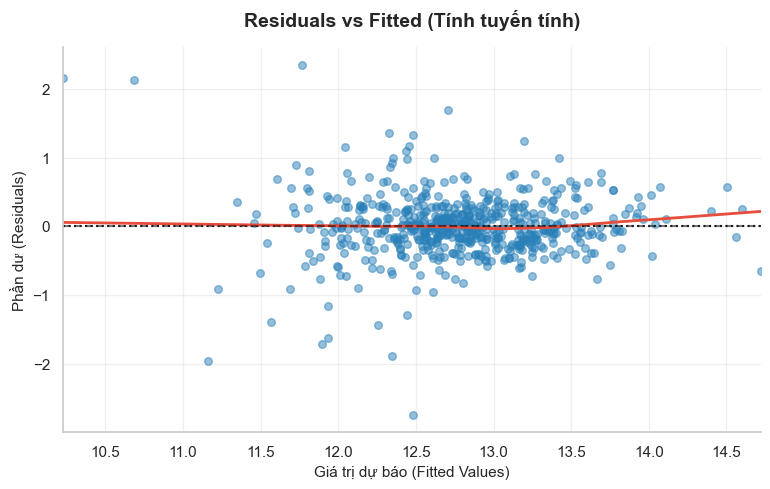

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
plt.figure(figsize=(9, 5))

# Vẽ scatter với đường lowess (đường xu hướng mượt) để dễ phát hiện pattern
sns.residplot(x=model.fittedvalues, y=model.resid, lowess=True, 
              scatter_kws={'alpha': 0.5, 's': 30, 'color': '#2980b9'},
              line_kws={'color': '#e74c3c', 'lw': 2})

plt.axhline(0, color='black', linestyle='--', alpha=0.5)
plt.title('Residuals vs Fitted (Tính tuyến tính)', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Giá trị dự báo (Fitted Values)', fontsize=11)
plt.ylabel('Phần dư (Residuals)', fontsize=11)
sns.despine()
plt.show()

**Nhan xet bieu do Residuals vs Fitted**

Cac phan du phan bo quanh duong 0 nhung van co mot so diem lech kha xa. Neu nhin tong the, bieu do khong cho thay dang hinh pheu qua ro, nen chua co bang chung truc quan manh ve phuong sai thay doi nghiem trong. Tuy nhien, do ton tai ngoai lai va sai so lon o mot so quan sat, gia dinh phuong sai khong doi chi nen duoc xem la tuong doi.

Trong boi canh du lieu gia nha, hien tuong sai so thay doi theo muc gia la kha thuong gap. Vi vay, neu can suy luan thong ke chat che hon, co the can nhac dung sai so chuan robust hoac kiem dinh Breusch-Pagan de bo sung cho nhan xet tu bieu do.


<Figure size 700x600 with 0 Axes>

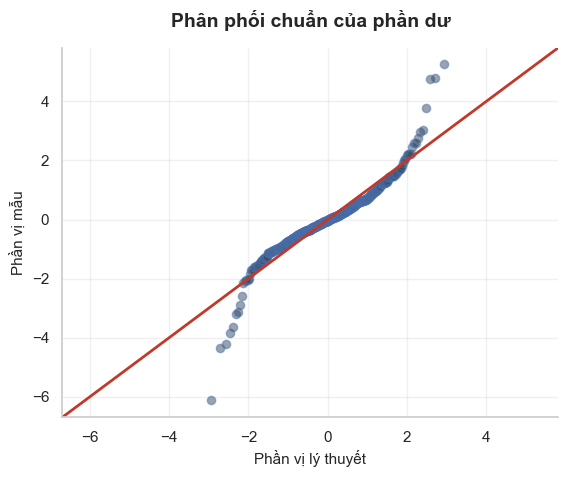

In [28]:
import statsmodels.api as sm

plt.figure(figsize=(7, 6))
# Sử dụng trực tiếp sm.qqplot nhưng tinh chỉnh màu sắc
fig = sm.qqplot(model.resid, line='45', fit=True)

# Lấy các line trong fig để đổi màu cho "pro"
ax = fig.gca()
ax.get_lines()[0].set_markerfacecolor('#34495e')
ax.get_lines()[0].set_alpha(0.5)
ax.get_lines()[1].set_color('#c0392b')
ax.get_lines()[1].set_linewidth(2)

plt.title('Phân phối chuẩn của phần dư', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Phần vị lý thuyết', fontsize=11)
plt.ylabel('Phần vị mẫu', fontsize=11)
sns.despine()
plt.show()

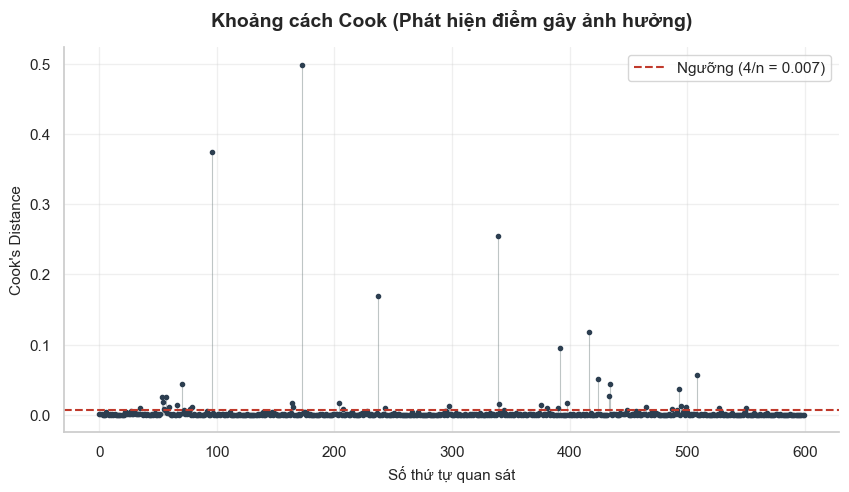

In [29]:
plt.figure(figsize=(10, 5))

# Vẽ biểu đồ stem nhưng làm mịn hơn
markerline, stemlines, baseline = plt.stem(np.arange(len(diagnostic_df)), 
                                           diagnostic_df['Cook_Distance'], 
                                           basefmt=" ")
plt.setp(stemlines, 'color', '#7f8c8d', 'linewidth', 0.8, 'alpha', 0.5)
plt.setp(markerline, 'color', '#2c3e50', 'markersize', 3)

# Đường ngưỡng 4/n
plt.axhline(cook_threshold, color='#c0392b', linestyle='--', linewidth=1.5, label=f'Ngưỡng (4/n = {cook_threshold:.3f})')

plt.title("Khoảng cách Cook (Phát hiện điểm gây ảnh hưởng)", fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Số thứ tự quan sát', fontsize=11)
plt.ylabel('Cook\'s Distance', fontsize=11)
plt.legend()
sns.despine()
plt.show()

## 11. Kiem tra da cong tuyen bang VIF

Cong thuc:

$$VIF_j=\frac{1}{1-R_j^2}$$

Nguong tham khao: `VIF < 5` thuong duoc xem la chua co da cong tuyen nghiem trong; `VIF > 10` la dang lo ngai.


In [30]:
vif_rows = []
X_for_vif = sm.add_constant(model_df[feature_cols])
for i, col in enumerate(X_for_vif.columns):
    if col == 'const':
        continue
    vif_rows.append({
        'Variable': col,
        'VIF': variance_inflation_factor(X_for_vif.values, i)
    })

vif_table = pd.DataFrame(vif_rows).sort_values('VIF', ascending=False)
display(vif_table.round(3))


,Variable,VIF
9,HomeType_SINGLE_FAMILY,4.643
10,HomeType_TOWNHOUSE,3.363
0,LogSqft,3.207
3,Baths,2.649
2,Beds,2.188
8,HomeType_MULTI_FAMILY,1.887
7,HomeType_MANUFACTURED,1.834
4,LogTaxValue,1.436
1,LogLotSize,1.301
5,Latitude,1.104


**Nhan xet output VIF**

Cac VIF deu nho hon 5, trong do lon nhat la `HomeType_SINGLE_FAMILY` khoang `4.643`, tiep theo la `HomeType_TOWNHOUSE` khoang `3.363` va `LogSqft` khoang `3.207`. Nhu vay, mo hinh chua co dau hieu da cong tuyen nghiem trong.

Mot so bien co VIF tren 3 cho thay van co tuong quan nhat dinh giua cac bien giai thich, dac biet giua loai nha, dien tich va so phong. Tuy nhien muc nay chua du lon de gay lo ngai lon ve do on dinh cua he so hoi quy.


## 12. Ket luan phan xay dung mo hinh

Mo hinh log tuyen tinh co kha nang giai thich tuong doi tot bien dong cua gia ban nha, voi `R^2` khoang 60.49% va kiem dinh F tong the co y nghia thong ke rat manh. Cac bien quan trong nhat trong mo hinh la `LogTaxValue`, `Baths` va `LogSqft`. Dieu nay phu hop voi thuc te thi truong: gia tri tinh thue, quy mo su dung va muc tien nghi cua can nha thuong lien quan chat che den gia ban.

Tuy nhien, mo hinh van con han che khi du bao tung can nha rieng le. Sai so du bao con kha lon, phan du co ngoai lai, va mot so quan sat co leverage/Cook Distance cao. Vi vay, mo hinh phu hop hon cho muc tieu phan tich xu huong va nhan dien yeu to anh huong chinh, hon la dinh gia chinh xac tuyet doi cho tung bat dong san.

De cai thien mo hinh, co the bo sung them bien ve tinh trang nha, nam xay dung, khoang cach den trung tam, chat luong truong hoc, tien ich khu vuc hoac dung cac phuong phap ben vung hon voi ngoai lai.
